# 00. Quick start: predict accessibility with the pretrained model

This page runs the pretrained Bolero model (registry key `Borzoi10M`, trained on the
Bolero-10M corpus) forward on a
few held-out genomic windows for five blood cell types, and compares its predictions with
the measured single-cell ATAC signal. It needs nothing from the other tutorials: every input
downloads from the public HuggingFace repositories
[`arcinstitute/bolero-models`](https://huggingface.co/arcinstitute/bolero-models) and
[`arcinstitute/bolero-data`](https://huggingface.co/datasets/arcinstitute/bolero-data).

**Requirements.** A Linux machine with one NVIDIA GPU (driver CUDA ≥ 12.0) and the
environment from `pixi install`. About 25 GB of free disk space for the downloads and the
unpacked files.

**Run it.** From the repository root:

```bash
pixi install
pixi run quickstart     # executes this notebook in place
```

**Downloads (first run only).** All of them are cached, so a second run downloads nothing.

| What | From | Size |
|---|---|---|
| Bolero checkpoint and config | `arcinstitute/bolero-models` | 4.8 GB |
| Flashzoi backbone weights (fold 0) | `johahi/flashzoi-replicate-0` | 0.8 GB |
| ChromiumPBMC measured signal (32 bp store) | `arcinstitute/bolero-data` | 5.3 GB |
| ChromiumPBMC reference signal, peaks, cell-state records | `arcinstitute/bolero-data` | 0.3 GB |
| hg38 genome FASTA | UCSC | 1.0 GB |

Downloads go to the bolerodata cache (`$BOLERODATA_HOME`, default `~/.cache/bolero`) and the
genome to `$BOLERO_DATA_DIR`. Set both to a large disk before you run, if needed.

**Expected output.** The notebook writes to `quickstart_output/` next to it:

- `pred_peak_data.feather`, `true_peak_data.feather`: predicted and measured accessibility
  of each ATAC peak in the predicted windows (rows: peaks; columns: the five cell states).
- `summary_stats.joblib.gz`: per-cell-state Pearson r and R² between the two, across peaks.
- `first_batch.joblib.gz`: the full first batch, with the 32 bp tracks.
- `batch/`, `config.joblib.gz`: per-batch outputs and the task configuration.
- `pred_vs_measured.png`: the figure at the end of this page. Left: predicted vs measured
  accessibility per peak, one colour per cell type. Right: the measured (filled) and
  predicted (line) 32 bp tracks of one window for each cell type.

**Expected run time.** First run: about 10 min of downloads and one-time setup with an
empty cache, most of it the hg38 FASTA and its one-hot store. Prediction: about 25 s on one
NVIDIA H100 80 GB. Later runs skip the
downloads. The last code cell prints both times for your run.

## Setup

In [1]:
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from bolero import Genome, init
from bolerodata import MODELS, get_flashzoi_checkpoint

assert torch.cuda.is_available(), "This quick start needs one NVIDIA GPU."
print("GPU:", torch.cuda.get_device_name(0))

init(num_cpus=8, object_store_memory_gb=16)
OUTPUT_DIR = Path("quickstart_output")

GPU: NVIDIA H100 80GB HBM3


2026-10-29 20:45:02,467	INFO worker.py:1781 -- Started a local Ray instance.


## The model and the dataset

`MODELS["Borzoi10M"]` is the Bolero accessibility model trained on the Bolero-10M corpus.
It is a multi-dataset model, so you tell it which dataset's cell states to predict (`model.dataset`).
That selects the dataset's conditioning encoder, peaks and measured signal. Here it is
**ChromiumPBMC**, 10x Multiome data of human peripheral blood mononuclear cells.

In [2]:
model = MODELS["Borzoi10M"]
model.dataset = "ChromiumPBMC"
model

config.json:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

BoleroModel(model_key=Borzoi10M)
  - Model group: BorzoiSignalMultiDS
  - Has gene count head: False
  - Score input: nan
  - Current Dataset: ChromiumPBMC

## Choose the cell states

A cell state is a **pseudobulk**: a pool of similar cells, described by its 30-dimensional
cell embedding, which conditions the model. The dataset's published pseudobulk records
annotate each pseudobulk with its cell type and flag two per cell type for inference. We
take the first flagged pseudobulk of five cell types. The records file we read is the one
`create_predictor` uses by default: pseudobulks pooled to about 5 million ATAC fragments
each.

In [3]:
# pseudobulks pooled to ~5 million fragments each (create_predictor's default)
records_path = model.dataset.get_meta_cell_pseudobulk_records_path(5_000_000)
annot = joblib.load(records_path)["pseudobulk_annot"]

CELL_TYPES = [
    "Classical_monocytes",
    "Naive_B_cells",
    "CD4__TCM_cell",
    "CD16__NK_cells",
    "pDC",
]
CELL_STATES = {
    annot.index[(annot["subclass"] == ct) & annot["Inference"]][0]: ct
    for ct in CELL_TYPES
}
pd.Series(CELL_STATES, name="cell type").rename_axis("pseudobulk")

index/meta_cell.condition_pseudobulk_rec(…):   0%|          | 0.00/6.21k [00:00<?, ?B/s]

pseudobulk/condition/ChromiumPBMC/pseudo(…):   0%|          | 0.00/5.43M [00:00<?, ?B/s]

pseudobulk
group8-pseudobulk4     Classical_monocytes
group7-pseudobulk17          Naive_B_cells
group5-pseudobulk22          CD4__TCM_cell
group1-pseudobulk9          CD16__NK_cells
group8-pseudobulk27                    pDC
Name: cell type, dtype: object

## Download the inputs

This cell fetches everything the prediction needs and times it. On a second run it only
checks the cache. `create_predictor` assembles the model and the data manager: the
checkpoint, the cell-state records, the peak BED, the reference bigWig (the model's
reference-signal input) and the 32 bp store that holds the measured signal.

In [4]:
t0 = time.perf_counter()
get_flashzoi_checkpoint(0)  # public backbone, renamed for bolero
_ = Genome("hg38").genome_one_hot  # FASTA from UCSC, then a one-hot store
predictor = model.create_predictor(
    pseudobulk_ids=list(CELL_STATES),
    sample_n_pseudobulks=None,  # predict exactly these cell states
)
DOWNLOAD_SECONDS = time.perf_counter() - t0
print(f"inputs ready in {DOWNLOAD_SECONDS / 60:.1f} min")

pytorch_model.bin:   0%|          | 0.00/788M [00:00<?, ?B/s]

UCSC url: https://hgdownload.soe.ucsc.edu/goldenpath/hg38/bigZips/hg38.fa.gz
Local path: /mnt/work/cache/bolero/data/hg38/fasta/hg38.fa



Unzipping /mnt/work/cache/bolero/data/hg38/fasta/hg38.fa.gz


Generating genome one-hot encoding


  0%|          | 0/25 [00:00<?, ?it/s]

...

pseudobulk/condition/NeurIPSBMMC/pseudob(…):   0%|          | 0.00/5.97M [00:00<?, ?B/s]

2026-10-29 20:54:13 - INFO - HTTP Request: HEAD https://huggingface.co/datasets/arcinstitute/bolero-data/resolve/main/pseudobulk/condition/ChromiumPBMC/pseudobulk_records_and_cond.cov5000000.joblib "HTTP/1.1 302 Found"


2026-10-29 20:54:18 - INFO - HTTP Request: HEAD https://huggingface.co/datasets/arcinstitute/bolero-data/resolve/main/metacell/parquet/ChromiumPBMC/ChromiumPBMC-MetaCell-32bp.tar "HTTP/1.1 302 Found"


metacell/parquet/ChromiumPBMC/ChromiumPB(…):   0%|          | 0.00/5.34G [00:00<?, ?B/s]

inputs ready in 9.5 min


## Predict

`regions="test_regions"` uses the windows of fold 0's held-out test chromosomes, which the
model never saw in training. Each window is 524,288 bp of DNA; the model predicts a 32 bp
accessibility track over it for each cell state. We keep 8 windows (`downsample_regions`).
The task also sums the track over each ATAC peak and compares it with the measured signal.

In [5]:
t0 = time.perf_counter()
predictor.prediction_task(
    output_dir=OUTPUT_DIR,
    regions="test_regions",
    downsample_regions=8,
    downsample_seed=0,
    batch_size=4,
    save_keys=[
        "__ytrue__:peak:cond1",  # measured per-peak accessibility
        "__ypred__:peak:cond1",  # predicted per-peak accessibility
        "region",
        "pseudobulk_ids",
        "peak",
    ],
    save_first_batch=True,  # keep the 32 bp tracks of the first batch
)
PREDICT_SECONDS = time.perf_counter() - t0
print(f"prediction finished in {PREDICT_SECONDS / 60:.1f} min")

Saving batches to /mnt/work/bolero/docs/tutorials/quickstart_output/batch
Saving stats to /mnt/work/bolero/docs/tutorials/quickstart_output/summary_stats.joblib.gz
0 regions has finished in /mnt/work/bolero/docs/tutorials/quickstart_output/batch
8 regions to compute
Data loader batch size 16


Loading base model weights from: /mnt/work/cache/bolerodata/flashzoi/fold_0.72040fb525d4.renamed.pt


Model does not have gene_count_output_head, skip
Loading checkpoint from /mnt/work/cache/bolerodata/hf/models--arcinstitute--bolero-models/snapshots/4a7f25be4d690417bd53decbeac4f83ec25b3917/BorzoiSignalMultiDS/Borzoi10M/checkpoint.pt


Skipping checkpoint encoders of datasets not in the config: ['CZIBodyAtlas', 'HYSocialRebound', 'Torpor+Control']


Dataloader Batch Schema:
- ChromiumPBMC.MetaCell:cov_scale: <class 'torch.Tensor'> torch.Size([10]) torch.float64 cuda:0
- __conditionemb__: <class 'torch.Tensor'> torch.Size([10, 1, 0]) torch.float32 cuda:0
- __conditionemb__:cond0: <class 'torch.Tensor'> torch.Size([5, 1, 0]) torch.float32 cuda:0
- __conditionemb__:cond1: <class 'torch.Tensor'> torch.Size([5, 1, 0]) torch.float32 cuda:0
- __conditionemb__:delta: <class 'torch.Tensor'> torch.Size([5, 1, 0]) torch.float32 cuda:0
- __dna__: <class 'torch.Tensor'> torch.Size([8, 4, 524288]) torch.uint8 cuda:0
- __embedding__: <class 'torch.Tensor'> torch.Size([10, 60]) torch.float32 cuda:0
- __embedding__:cond0: <class 'torch.Tensor'> torch.Size([5, 60]) torch.float32 cuda:0
- __embedding__:cond1: <class 'torch.Tensor'> torch.Size([5, 60]) torch.float32 cuda:0
- __embedding__:delta: <class 'torch.Tensor'> torch.Size([5, 60]) torch.float32 cuda:0
- __ypred__:cond1: <class 'torch.Tensor'> torch.Size([8, 5, 16352]) torch.float32 cuda:0
- __

Total time: 5.40s
Inference time: 3.71s or 3.710s per batch
Callback time: 0.21s or 0.210s per batch
(total 1 batches)

Saved Batch Schema:
- __ypred__:peak:cond1: <class 'numpy.ndarray'> (5, 598) float32
- __ytrue__:peak:cond1: <class 'numpy.ndarray'> (5, 598) float32
- peak: <class 'pandas.core.frame.DataFrame'> (598, 7)
- pseudobulk_ids: <class 'numpy.ndarray'> (10,) <U24
- region: <class 'numpy.ndarray'> (8,) <U25

Final Stats Batch Schema:
- condition_pairs: <class 'numpy.ndarray'> (5, 2) <U8
- peak: <class 'pandas.core.frame.DataFrame'> (598, 7)
- peak_pearsonr: <class 'numpy.ndarray'> (5,) float32
- peak_r2: <class 'numpy.ndarray'> (5,) float32
- pseudobulk_ids: <class 'numpy.ndarray'> (10,) <U24
- region: <class 'numpy.ndarray'> (8,) <U25

1 batches in /mnt/work/bolero/docs/tutorials/quickstart_output
prediction finished in 0.4 min


## Results

Per-peak accessibility, measured and predicted, and how well they agree for each cell type
(Pearson r across the peaks in the 8 windows, on log1p values).

In [6]:
pred = pd.read_feather(OUTPUT_DIR / "pred_peak_data.feather")
true = pd.read_feather(OUTPUT_DIR / "true_peak_data.feather")
print(pred.shape[0], "peaks x", pred.shape[1], "cell states")

agreement = pd.Series(
    {
        CELL_STATES[c]: np.corrcoef(np.log1p(true[c]), np.log1p(pred[c]))[0, 1]
        for c in pred.columns
    },
    name="Pearson r (log1p)",
)
agreement.round(3).to_frame()

598 peaks x 5 cell states


,Pearson r (log1p)
Classical_monocytes,0.929
Naive_B_cells,0.918
CD4__TCM_cell,0.918
CD16__NK_cells,0.895
pDC,0.880


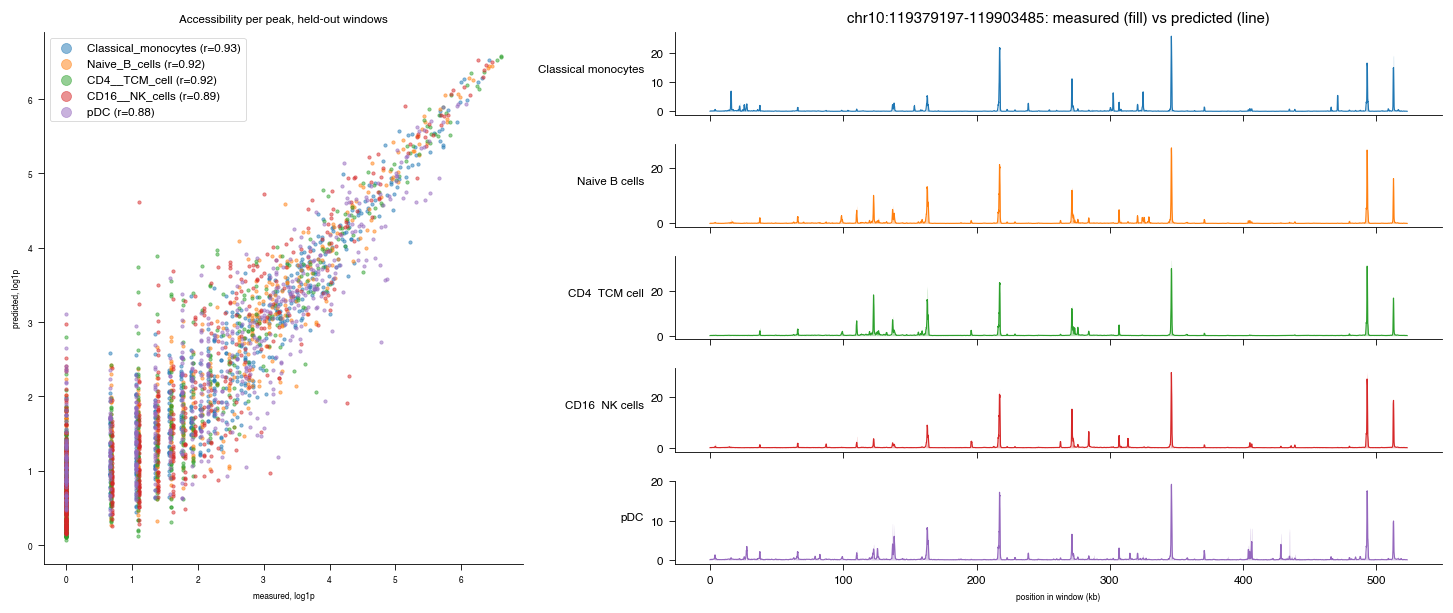

In [7]:
def to_np(x):
    return x.detach().cpu().numpy() if hasattr(x, "detach") else np.asarray(x)


batch = joblib.load(OUTPUT_DIR / "first_batch.joblib.gz")
ytrue = to_np(batch["__ytrue__:cond1"])  # (window, cell state, 32 bp bin)
ypred = to_np(batch["__ypred__:cond1"])
track_states = pred.columns  # same order as the peak tables
assert ytrue.shape[1] == ypred.shape[1] == len(track_states)
rid = 0
region = batch["region"][rid]

colors = plt.get_cmap("tab10").colors
fig = plt.figure(figsize=(12, 5), dpi=120, constrained_layout=True)
grid = fig.add_gridspec(len(track_states), 2, width_ratios=[1, 1.6])

ax = fig.add_subplot(grid[:, 0])
for i, c in enumerate(pred.columns):
    ax.scatter(
        np.log1p(true[c]),
        np.log1p(pred[c]),
        s=4,
        alpha=0.5,
        color=colors[i],
        label=f"{CELL_STATES[c]} (r={agreement[CELL_STATES[c]]:.2f})",
    )
ax.set(
    xlabel="measured, log1p",
    ylabel="predicted, log1p",
    title="Accessibility per peak, held-out windows",
)
ax.legend(fontsize=7, markerscale=3, loc="upper left")


def smooth(y):
    # display only: a 16-bin (512 bp) moving average
    return np.convolve(y, np.ones(16) / 16, mode="same")


x_kb = np.arange(ytrue.shape[-1]) * 32 / 1000
for i, c in enumerate(track_states):
    tax = fig.add_subplot(grid[i, 1])
    tax.fill_between(x_kb, smooth(ytrue[rid, i]), color=colors[i], alpha=0.35, lw=0)
    tax.plot(x_kb, smooth(ypred[rid, i]), color=colors[i], lw=0.7)
    tax.set_ylabel(CELL_STATES[c].replace("_", " "), rotation=0, ha="right", fontsize=7)
    tax.tick_params(labelsize=7)
    if i == 0:
        tax.set_title(f"{region}: measured (fill) vs predicted (line)", fontsize=9)
    if i < len(track_states) - 1:
        tax.set_xticklabels([])
tax.set_xlabel("position in window (kb)")
fig.savefig(OUTPUT_DIR / "pred_vs_measured.png")

In [8]:
print(f"downloads + setup : {DOWNLOAD_SECONDS / 60:.1f} min")
print(f"prediction        : {PREDICT_SECONDS / 60:.1f} min")
print("outputs in", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print("  ", p.name)

downloads + setup : 9.5 min
prediction        : 0.4 min
outputs in /mnt/work/bolero/docs/tutorials/quickstart_output
   batch
   config.joblib.gz
   first_batch.joblib.gz
   pred_peak_data.feather
   pred_vs_measured.png
   summary_stats.joblib.gz
   true_peak_data.feather


## Next

To predict your own windows, pass `regions=["chr1:1000000-1524288", ...]` or a DataFrame
to `prediction_task`; to predict other cell states, pass other `pseudobulk_ids` to
`create_predictor`. The [prediction tutorial](prediction/09_prediction_task.ipynb) explains
the inputs and outputs in more depth, and the
[variant-effect](prediction/10_qtl_task.ipynb) and
[attribution](prediction/11_attribution_task.ipynb) tutorials use the same model.